# 🧹 Noise Models & Image Restoration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/negarsh76/Digital-Image-Processing/blob/main/notebooks/04_noise_and_restoration.ipynb)

This notebook simulates **Gaussian**, **salt-and-pepper** and **uniform** noise, then removes it with **mean**, **geometric-mean**, **median** and **adaptive local noise-reduction** filters, compared by PSNR. It ends with **inverse filtering vs. Wiener filtering** of a motion-blurred, noisy image, which shows why naive inverse filtering fails.

In [1]:
# On Colab, uncomment:
# !pip -q install scikit-image opencv-python-headless

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import data, img_as_float
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "image.cmap": "gray"})
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)

def show(images, titles, ncols=None, figsize=None, save=None, cmap="gray"):
    """Plot a row/grid of images with titles; optionally save to assets/."""
    n = len(images); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize or (3.2 * ncols, 3.2 * nrows))
    for ax, im, t in zip(np.ravel(axes), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else cmap); ax.set_title(t); ax.axis("off")
    for ax in np.ravel(axes)[n:]: ax.axis("off")
    fig.tight_layout()
    if save: fig.savefig(ASSETS / save, bbox_inches="tight", dpi=120)
    plt.show()

def psnr(ref, img):
    mse = np.mean((np.asarray(ref, float) - np.asarray(img, float)) ** 2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


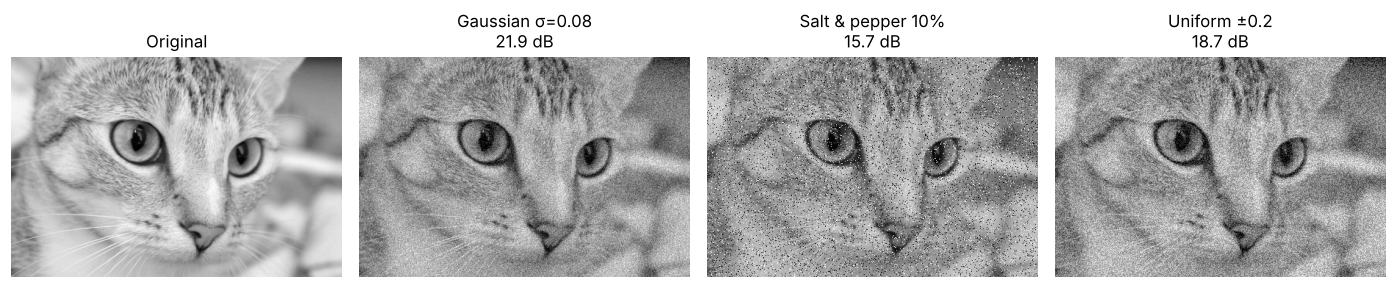

In [3]:
rng = np.random.default_rng(0)
img = img_as_float(data.chelsea()[..., 0])

def gaussian_noise(f, sigma=0.08):  return np.clip(f + rng.normal(0, sigma, f.shape), 0, 1)
def uniform_noise(f, a=0.2):        return np.clip(f + rng.uniform(-a, a, f.shape), 0, 1)
def salt_pepper(f, p=0.1):
    g = f.copy(); u = rng.random(f.shape)
    g[u < p / 2] = 0; g[u > 1 - p / 2] = 1
    return g

noisy = {"Gaussian σ=0.08": gaussian_noise(img), "Salt & pepper 10%": salt_pepper(img), "Uniform ±0.2": uniform_noise(img)}
show([img] + list(noisy.values()), ["Original"] + [f"{k}\n{psnr(img, v):.1f} dB" for k, v in noisy.items()], save="noise_models.png")

## Order-statistic & mean filters
All the filters work on a sliding $m\times n$ window $S_{xy}$:

* **Arithmetic mean:** $\hat f = \frac{1}{mn}\sum g$
* **Geometric mean:** $\hat f = \left(\prod g\right)^{1/mn}$. It smooths about as much as the arithmetic mean but keeps more detail.
* **Median:** $\hat f = \operatorname{median}(g)$. It works best on impulse (salt-and-pepper) noise.
* **Adaptive local noise reduction:** $\hat f = g - \frac{\sigma_\eta^2}{\sigma_L^2}(g - m_L)$, where $m_L$ and $\sigma_L^2$ are the local mean and variance. It smooths flat regions and leaves edges alone.

In [4]:
from numpy.lib.stride_tricks import sliding_window_view as windows

def _win(g, k):  return windows(np.pad(g, k // 2, mode="symmetric"), (k, k))
def mean_filter(g, k=3):      return _win(g, k).mean(axis=(-1, -2))
def geometric_mean(g, k=3):   return np.exp(np.log(np.clip(_win(g, k), 1e-6, None)).mean(axis=(-1, -2)))
def median_filter(g, k=3):    return np.median(_win(g, k), axis=(-1, -2))
def adaptive_filter(g, k=7, noise_var=None):
    w = _win(g, k); mL, vL = w.mean((-1, -2)), w.var((-1, -2))
    nv = np.median(vL) if noise_var is None else noise_var          # estimate σ_η² from flat areas
    ratio = np.minimum(nv / np.maximum(vL, 1e-12), 1.0)              # never let it exceed 1
    return g - ratio * (g - mL)

filters = {"Mean 3×3": mean_filter, "Geometric 3×3": geometric_mean, "Median 3×3": median_filter, "Adaptive 7×7": adaptive_filter}

In [5]:
import pandas as pd
table = pd.DataFrame({noise: {"(noisy)": psnr(img, g), **{fn: psnr(img, f(g)) for fn, f in filters.items()}}
                      for noise, g in noisy.items()}).round(2)
table.style.highlight_max(axis=0, color="#c6f6d5").format("{:.2f} dB")

,Gaussian σ=0.08,Salt & pepper 10%,Uniform ±0.2
(noisy),21.94 dB,15.68 dB,18.75 dB
Mean 3×3,29.35 dB,24.29 dB,27.12 dB
Geometric 3×3,28.79 dB,10.72 dB,26.34 dB
Median 3×3,28.08 dB,33.15 dB,23.96 dB
Adaptive 7×7,29.57 dB,24.13 dB,28.41 dB


**Takeaways:** the **median** filter wins clearly on salt-and-pepper noise. The **geometric mean** fails badly there, because a single pepper pixel (value 0) pulls the whole product to 0. The **adaptive** filter is the best all-rounder for Gaussian and uniform noise, since it smooths flat regions and leaves edges alone.

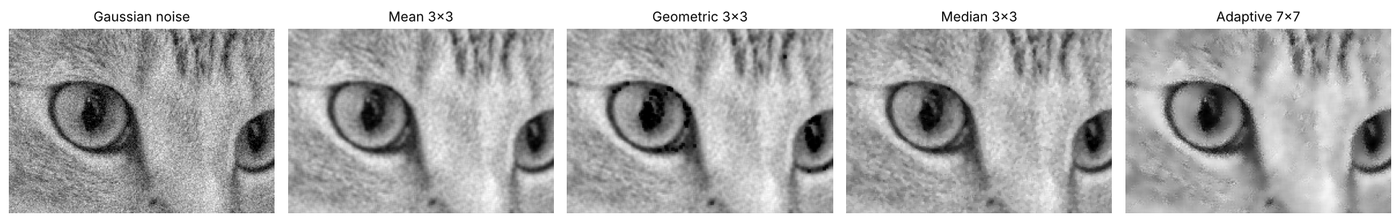

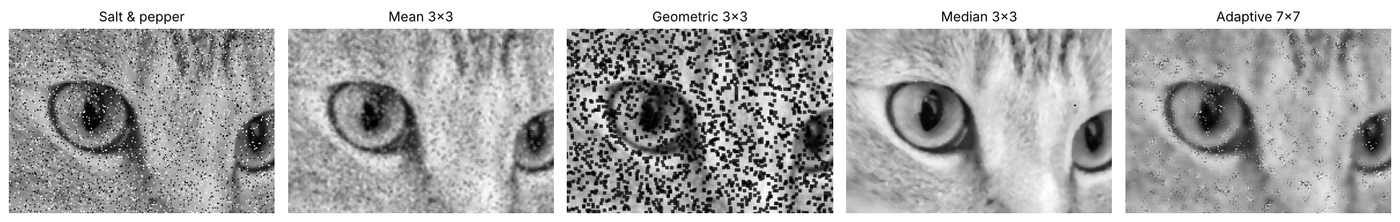

In [6]:
g = noisy["Gaussian σ=0.08"]
crop = np.s_[40:200, 100:330]
show([g[crop]] + [f(g)[crop] for f in filters.values()], ["Gaussian noise"] + list(filters), ncols=5, save="denoise_gaussian.png")
g = noisy["Salt & pepper 10%"]
show([g[crop]] + [f(g)[crop] for f in filters.values()], ["Salt & pepper"] + list(filters), ncols=5, save="denoise_sp.png")

## Inverse vs. Wiener filtering
Degradation model in the frequency domain: $G = H\,F + N$.

* **Inverse filter:** $\hat F = G / H$. Wherever $H\approx 0$ the noise term $N/H$ blows up.
* **Wiener filter:** $\hat F = \dfrac{H^*}{|H|^2 + K}\,G$, where $K\approx S_\eta/S_f$ keeps the division well-behaved.
* **Cut-off inverse filter:** only invert inside a radius $D_0$. It is a common middle ground.

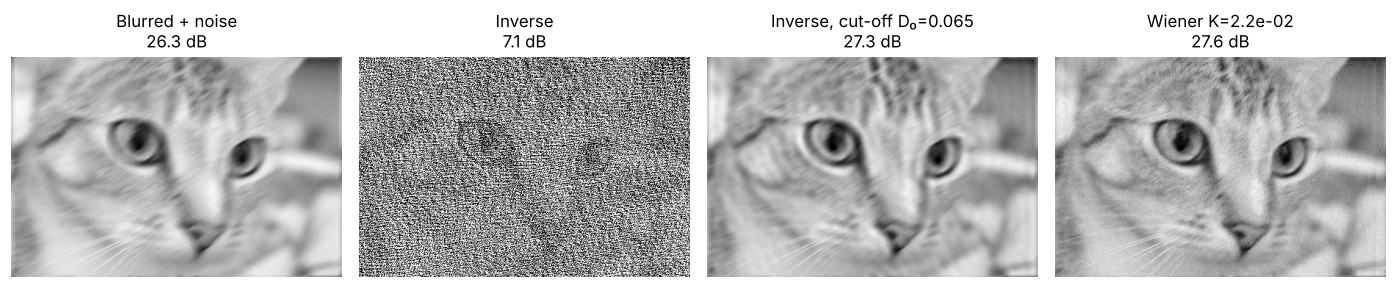

In [7]:
def motion_psf(shape, length=15, angle=30):
    """Linear motion-blur PSF centred in an array of `shape`."""
    psf = np.zeros(shape); c = np.array(shape) // 2
    t = np.deg2rad(angle)
    for s in np.linspace(-length / 2, length / 2, 4 * length):
        r, q = int(round(c[0] - s * np.sin(t))), int(round(c[1] + s * np.cos(t)))
        psf[r, q] = 1
    return psf / psf.sum()

F = np.fft.fft2(img)
H = np.fft.fft2(np.fft.ifftshift(motion_psf(img.shape)))
blurred = np.real(np.fft.ifft2(F * H))
g = blurred + rng.normal(0, 0.01, img.shape)          # small additive noise
G = np.fft.fft2(g)

inverse = np.real(np.fft.ifft2(G / np.where(np.abs(H) < 1e-3, 1e-3, H)))
u, v = np.meshgrid(np.fft.fftfreq(img.shape[0]), np.fft.fftfreq(img.shape[1]), indexing="ij")
def cutoff_inverse(D0):
    Hs = np.where(np.abs(H) < 1e-3, 1e-3, H)
    return np.real(np.fft.ifft2(np.where(np.hypot(u, v) < D0, G / Hs, G)))
D0s = np.linspace(0.01, 0.2, 39)
D0 = D0s[np.argmax([psnr(img, np.clip(cutoff_inverse(d), 0, 1)) for d in D0s])]
cutoff = cutoff_inverse(D0)
wiener = lambda K: np.real(np.fft.ifft2(np.conj(H) / (np.abs(H)**2 + K) * G))

Ks = np.logspace(-4, -0.5, 25)
best_K = Ks[np.argmax([psnr(img, np.clip(wiener(K), 0, 1)) for K in Ks])]
results = {"Blurred + noise": g, "Inverse": inverse, f"Inverse, cut-off D₀={D0:.3f}": cutoff, f"Wiener K={best_K:.1e}": wiener(best_K)}
show([np.clip(r, 0, 1) for r in results.values()], [f"{k}\n{psnr(img, np.clip(r, 0, 1)):.1f} dB" for k, r in results.items()],
     save="wiener.png")

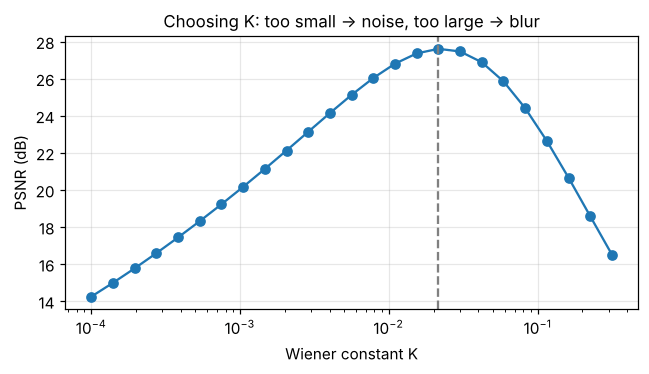

In [8]:
plt.figure(figsize=(6, 3.5))
plt.semilogx(Ks, [psnr(img, np.clip(wiener(K), 0, 1)) for K in Ks], "o-")
plt.axvline(best_K, ls="--", c="gray"); plt.xlabel("Wiener constant K"); plt.ylabel("PSNR (dB)")
plt.title("Choosing K: too small → noise, too large → blur"); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(ASSETS / "wiener_K.png", dpi=120); plt.show()